In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

warnings.filterwarnings("ignore")
SEED = 42
DATA_PATH = "Crop_recommendation.csv"   # change to your exact file name
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
ADD_ARTIFICIAL_NOISE = True             # set False to skip the injected noise

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
print(df.isna().sum())
display(df.describe().T)
print(df[TARGET].nunique(), "crops:", sorted(df[TARGET].unique()))

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


22 crops: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


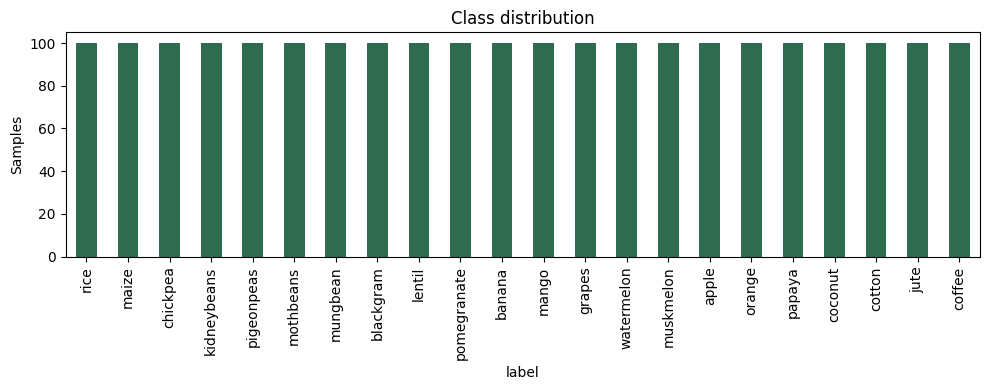

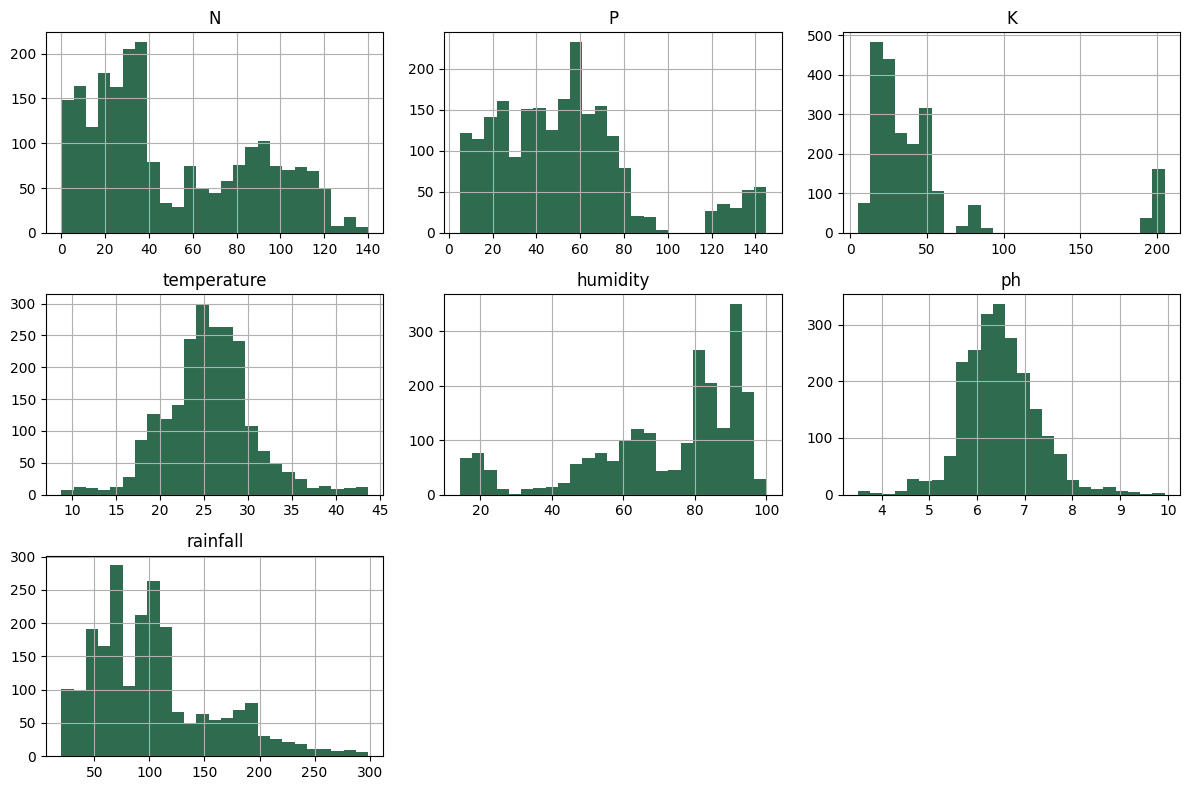

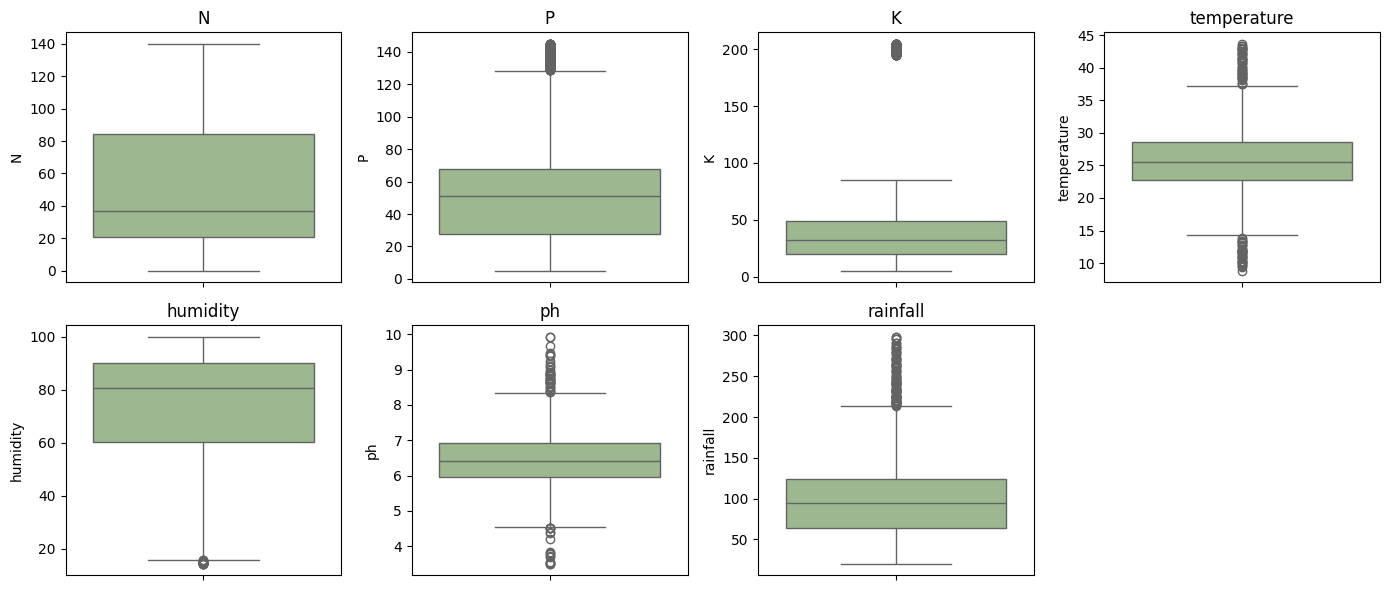

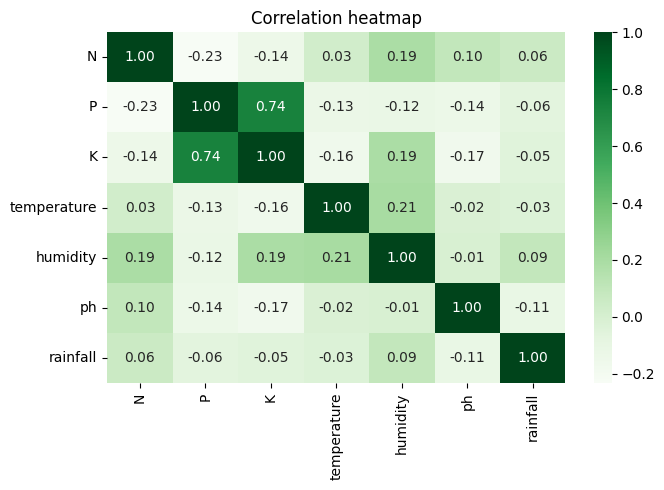

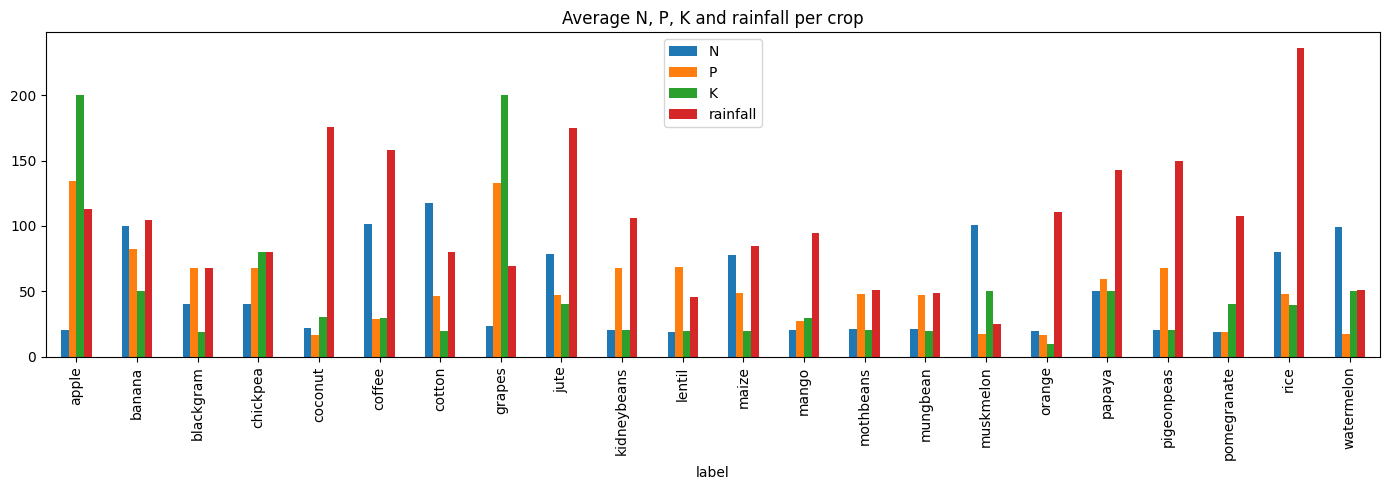

In [2]:
plt.figure(figsize=(10, 4))
df[TARGET].value_counts().plot(kind="bar", color="#2f6b4f")
plt.title("Class distribution"); plt.ylabel("Samples"); plt.tight_layout()
plt.savefig("figures/eda_class_distribution.png", dpi=150); plt.show()

df[FEATURES].hist(bins=25, figsize=(12, 8), color="#2f6b4f")
plt.tight_layout(); plt.savefig("figures/eda_histograms.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="#9bbf8a"); ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("figures/eda_boxplots.png", dpi=150); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="Greens")
plt.title("Correlation heatmap"); plt.tight_layout()
plt.savefig("figures/eda_correlation_heatmap.png", dpi=150); plt.show()

avg = df.groupby(TARGET)[FEATURES].mean()
avg[["N", "P", "K", "rainfall"]].plot(kind="bar", figsize=(14, 5))
plt.title("Average N, P, K and rainfall per crop"); plt.tight_layout()
plt.savefig("figures/avg_nutrients_per_crop.png", dpi=150); plt.show()

In [3]:
raw = df.copy()
if ADD_ARTIFICIAL_NOISE:
    rng = np.random.default_rng(SEED)
    n = len(raw)
    for col in FEATURES:
        idx = rng.choice(n, size=int(0.02 * n), replace=False)
        raw.loc[idx, col] = np.nan                    # about 2% missing per feature
    for col in ["rainfall", "K"]:
        idx = rng.choice(n, size=5, replace=False)
        raw.loc[idx, col] = raw[col].max() * 2        # 5 extreme values in two features
print("Missing per column:\n", raw.isna().sum())

dups = raw.duplicated().sum()
print("Exact duplicate rows found:", dups)
raw = raw.drop_duplicates().reset_index(drop=True)

le = LabelEncoder()
y = pd.Series(le.fit_transform(raw[TARGET]), name="y")
X_raw = raw[FEATURES].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train_raw.shape, " Test:", X_test_raw.shape)

Missing per column:
 N              44
P              44
K              44
temperature    44
humidity       44
ph             44
rainfall       44
label           0
dtype: int64
Exact duplicate rows found: 0
Train: (1760, 7)  Test: (440, 7)


Missing values left in Setup B train: 0
Values capped by outlier rule (train): 491


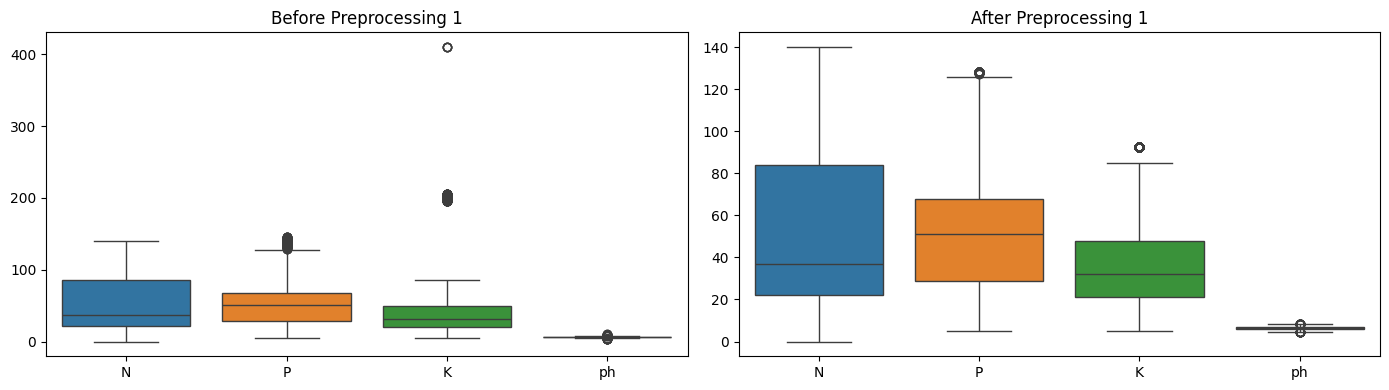

In [4]:
# Setup A: raw (missing values become 0 only so the models can run)
XA_train = X_train_raw.fillna(0)
XA_test = X_test_raw.fillna(0)

# Preprocessing 1: fitted on training data only
medians = X_train_raw.median()
q1, q3 = X_train_raw.quantile(0.25), X_train_raw.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

def preprocessing_1(X):
    X = X.fillna(medians)
    return X.clip(lower=lower, upper=upper, axis=1)

XB_train = preprocessing_1(X_train_raw)
XB_test = preprocessing_1(X_test_raw)

# Preprocessing 2: scaling, fitted on training data only
scaler = StandardScaler().fit(XB_train)
XC_train = pd.DataFrame(scaler.transform(XB_train), columns=FEATURES, index=XB_train.index)
XC_test = pd.DataFrame(scaler.transform(XB_test), columns=FEATURES, index=XB_test.index)

print("Missing values left in Setup B train:", int(XB_train.isna().sum().sum()))
print("Values capped by outlier rule (train):",
      int((XB_train != X_train_raw.fillna(medians)).sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=X_train_raw[["N", "P", "K", "ph"]], ax=axes[0]); axes[0].set_title("Before Preprocessing 1")
sns.boxplot(data=XB_train[["N", "P", "K", "ph"]], ax=axes[1]); axes[1].set_title("After Preprocessing 1")
plt.tight_layout(); plt.savefig("figures/boxplots_before_after_p1.png", dpi=150); plt.show()

In [5]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

def make_models():
    return {
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
        "KNN": KNeighborsClassifier(),
        "Naive Bayes": GaussianNB(),
        "Logistic Regression": LogisticRegression(max_iter=3000),
        "SVM": SVC(probability=True, random_state=SEED),
    }

setups = {
    "A: Raw data": (XA_train, XA_test),
    "B: After Preprocessing 1": (XB_train, XB_test),
    "C: After Preprocessing 1 + 2": (XC_train, XC_test),
}

rows = []
for setup_name, (Xtr, Xte) in setups.items():
    for model_name, model in make_models().items():
        model.fit(Xtr, y_train)
        pred = model.predict(Xte)
        p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted", zero_division=0)
        rows.append({"Setup": setup_name, "Model": model_name,
                     "Accuracy": accuracy_score(y_test, pred),
                     "Precision": p, "Recall": r, "F1": f1})

results = pd.DataFrame(rows)
results.to_csv("outputs/model_comparison_all.csv", index=False)

acc_table = (results.pivot(index="Setup", columns="Model", values="Accuracy") * 100).round(2)
acc_table.to_csv("outputs/three_way_accuracy_table.csv")
display(acc_table)    # this goes into report section 8.1

Model,Decision Tree,KNN,Logistic Regression,Naive Bayes,Random Forest,SVM
Setup,,,,,,
A: Raw data,94.09,91.14,86.36,90.68,97.95,91.36
B: After Preprocessing 1,97.05,95.91,93.41,98.41,98.64,96.59
C: After Preprocessing 1 + 2,97.05,96.14,96.14,98.41,98.64,97.95


In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = {}
for name, model in make_models().items():
    s = cross_val_score(model, XC_train, y_train, cv=cv, scoring="accuracy")
    cv_scores[name] = (s.mean(), s.std())

cv_table = pd.DataFrame(cv_scores, index=["CV mean", "CV std"]).T.sort_values("CV mean", ascending=False)
display((cv_table * 100).round(2))
cv_table.to_csv("outputs/cv_scores_setup_c.csv")

best_name = cv_table.index[0]
print("Best model by 5-fold CV:", best_name)

,CV mean,CV std
Random Forest,98.52,0.21
Naive Bayes,97.78,0.42
SVM,96.76,0.73
KNN,96.02,1.00
Decision Tree,95.51,0.58
Logistic Regression,94.26,0.73


Best model by 5-fold CV: Random Forest


In [7]:
from sklearn.metrics import recall_score

rows = []
for setup_name, (Xtr, Xte) in setups.items():
    m = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr, y_train)
    rec = recall_score(y_test, m.predict(Xte), average=None)
    for crop in ["apple", "grapes"]:
        rows.append({"Setup": setup_name, "Crop": crop,
                     "Recall %": round(100 * rec[list(le.classes_).index(crop)], 1)})
display(pd.DataFrame(rows).pivot(index="Setup", columns="Crop", values="Recall %"))

Crop,apple,grapes
Setup,,
A: Raw data,100.0,100.0
B: After Preprocessing 1,100.0,100.0
C: After Preprocessing 1 + 2,100.0,100.0


Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.9858
Held-out accuracy: 0.9864
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       0.95      1.00      0.98        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      0.95      0.97        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      0.90      0.92        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       1.00      1.00      1.00        20
  

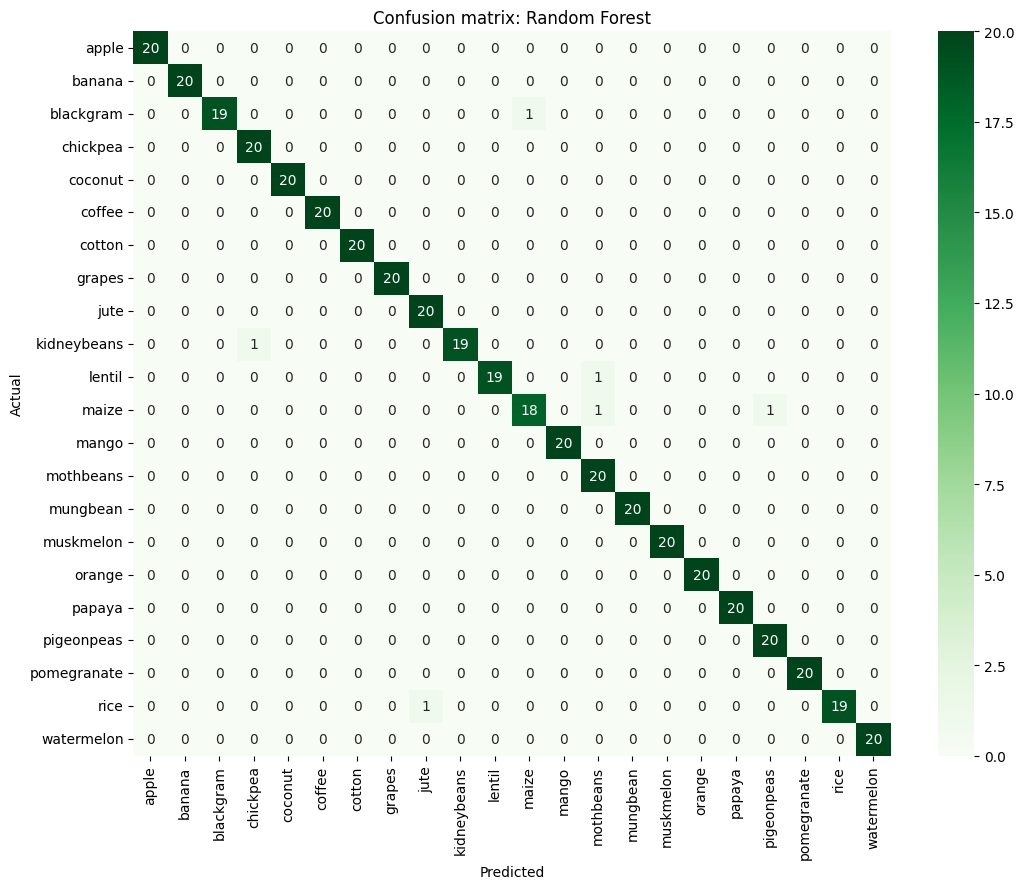

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

param_grids = {
    "Random Forest": {"n_estimators": [100, 200, 400], "max_depth": [None, 10, 20], "min_samples_split": [2, 5]},
    "Naive Bayes": {"var_smoothing": [1e-9, 1e-8, 1e-7]},
    "SVM": {"C": [0.5, 1, 5, 10], "kernel": ["rbf", "linear"]},
    "KNN": {"n_neighbors": [3, 5, 7, 9], "weights": ["uniform", "distance"]},
    "Decision Tree": {"max_depth": [None, 8, 12, 16], "min_samples_split": [2, 5, 10]},
    "Logistic Regression": {"C": [0.1, 1, 10, 100]},
}

grid = GridSearchCV(make_models()[best_name], param_grids[best_name],
                    cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(XC_train, y_train)
final_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV accuracy: %.4f" % grid.best_score_)

pred = final_model.predict(XC_test)
print("Held-out accuracy: %.4f" % accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=le.classes_, zero_division=0))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion matrix: " + best_name)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig("figures/confusion_matrix_best.png", dpi=150); plt.show()

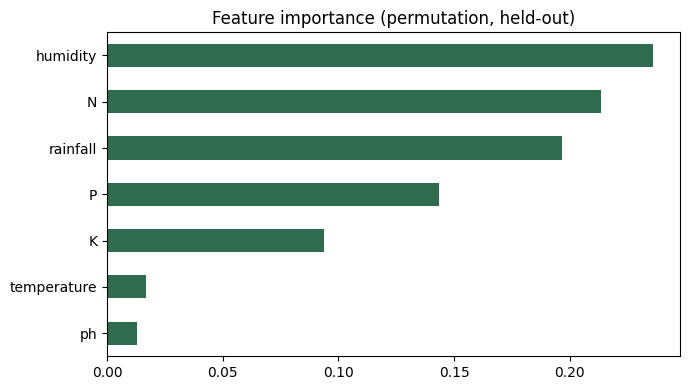

humidity       0.235909
N              0.213636
rainfall       0.196818
P              0.143409
K              0.093864
temperature    0.016818
ph             0.012727
dtype: float64


In [9]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final_model, XC_test, y_test, n_repeats=10, random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp_s.plot(kind="barh", color="#2f6b4f", figsize=(7, 4))
plt.title("Feature importance (permutation, held-out)")
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=150); plt.show()
print(imp_s.sort_values(ascending=False))

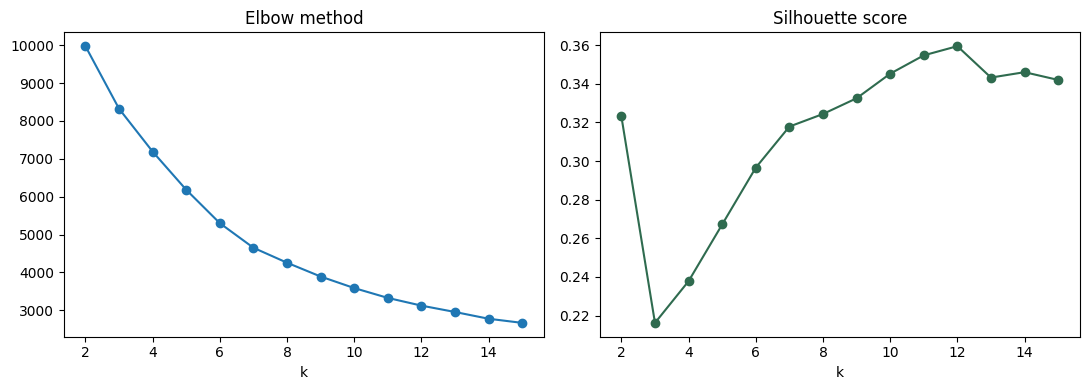

Chosen k = 12


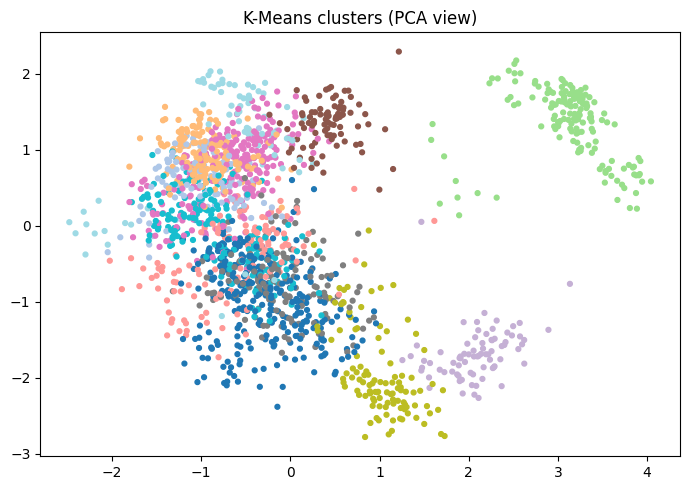

col_0,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,lentil,maize,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
row_0,,,,,,,,,,,,,,,,,,,,,,
0,0,0,80,0,0,0,1,0,0,0,76,1,7,48,80,0,0,3,5,0,0,0
1,0,0,0,0,80,0,0,0,0,0,0,0,0,0,0,0,12,0,0,11,1,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,80,0,1,0,0,0,80
3,80,0,0,1,0,0,0,80,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,3,0,0,0,0,0,0,56,0,1,69,0,0
5,0,0,0,76,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
6,0,79,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,5,0,0,0,0
7,0,1,0,0,0,57,0,0,80,0,1,0,0,0,0,0,0,11,1,0,77,0
8,0,0,0,0,0,0,0,0,0,1,0,0,73,32,0,0,0,0,41,0,0,0


In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ks = range(2, 16)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(XC_train)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(XC_train, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, marker="o", color="#2f6b4f"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("figures/elbow_silhouette.png", dpi=150); plt.show()

K = int(list(ks)[int(np.argmax(sil))])
print("Chosen k =", K)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(XC_train)
coords = PCA(n_components=2, random_state=SEED).fit_transform(XC_train)
plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], c=km.labels_, cmap="tab20", s=12)
plt.title("K-Means clusters (PCA view)")
plt.tight_layout(); plt.savefig("figures/cluster_visualization.png", dpi=150); plt.show()

pd.set_option("display.max_columns", 30)
display(pd.crosstab(km.labels_, le.inverse_transform(y_train.loc[XC_train.index])))

In [11]:
from sklearn.model_selection import cross_val_predict

proba = cross_val_predict(final_model, XC_train, y_train, cv=cv, method="predict_proba")
top_p = proba.max(axis=1)
correct = proba.argmax(axis=1) == y_train.values
print("Correct predictions, median top probability: %.2f" % np.median(top_p[correct]))
if (~correct).any():
    print("Wrong predictions, median top probability: %.2f" % np.median(top_p[~correct]))
for t in [0.4, 0.5, 0.6, 0.7]:
    flagged = top_p < t
    print(f"threshold {t:.0%}: flags {flagged.mean():.1%} of cases, "
          f"catches {(flagged & ~correct).sum()} of {(~correct).sum()} wrong predictions")

Correct predictions, median top probability: 0.97
Wrong predictions, median top probability: 0.51
threshold 40%: flags 1.4% of cases, catches 9 of 25 wrong predictions
threshold 50%: flags 2.3% of cases, catches 10 of 25 wrong predictions
threshold 60%: flags 4.7% of cases, catches 16 of 25 wrong predictions
threshold 70%: flags 7.3% of cases, catches 22 of 25 wrong predictions


In [12]:
import joblib

os.makedirs("artifacts", exist_ok=True)
joblib.dump(final_model, "artifacts/model.joblib")
joblib.dump(scaler, "artifacts/scaler.joblib")
joblib.dump(le, "artifacts/label_encoder.joblib")

ranges = {"features": FEATURES,
          "ranges": {c: {"min": float(XB_train[c].min()), "max": float(XB_train[c].max())} for c in FEATURES}}
json.dump(ranges, open("artifacts/training_ranges.json", "w"), indent=2)

train_labels = le.inverse_transform(y_train.loc[XB_train.index])
profiles = {}
for crop in le.classes_:
    sub = XB_train[train_labels == crop]
    profiles[crop] = {c: {"low": float(sub[c].quantile(0.10)),
                          "median": float(sub[c].median()),
                          "high": float(sub[c].quantile(0.90))} for c in FEATURES}
json.dump(profiles, open("artifacts/crop_profiles.json", "w"), indent=2)
print(os.listdir("artifacts"))

!zip -r results.zip figures outputs artifacts
from google.colab import files
files.download("results.zip")

['label_encoder.joblib', 'model.joblib', 'scaler.joblib', 'training_ranges.json', 'crop_profiles.json']
  adding: figures/ (stored 0%)
  adding: figures/cluster_visualization.png (deflated 2%)
  adding: figures/avg_nutrients_per_crop.png (deflated 18%)
  adding: figures/elbow_silhouette.png (deflated 11%)
  adding: figures/confusion_matrix_best.png (deflated 22%)
  adding: figures/eda_class_distribution.png (deflated 18%)
  adding: figures/eda_histograms.png (deflated 27%)
  adding: figures/eda_boxplots.png (deflated 23%)
  adding: figures/boxplots_before_after_p1.png (deflated 24%)
  adding: figures/eda_correlation_heatmap.png (deflated 9%)
  adding: figures/feature_importance.png (deflated 24%)
  adding: outputs/ (stored 0%)
  adding: outputs/three_way_accuracy_table.csv (deflated 31%)
  adding: outputs/cv_scores_setup_c.csv (deflated 37%)
  adding: outputs/model_comparison_all.csv (deflated 72%)
  adding: artifacts/ (stored 0%)
  adding: artifacts/label_encoder.joblib (deflated 36%)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Ranges and profiles from the ORIGINAL clean training rows (not the capped ones)
clean_train = df.loc[X_train_raw.index, FEATURES]

ranges = {"features": FEATURES,
          "ranges": {c: {"min": float(clean_train[c].min()), "max": float(clean_train[c].max())} for c in FEATURES}}
json.dump(ranges, open("artifacts/training_ranges.json", "w"), indent=2)

train_labels = le.inverse_transform(y_train.loc[clean_train.index])
profiles = {}
for crop in le.classes_:
    sub = clean_train[train_labels == crop]
    profiles[crop] = {c: {"low": float(sub[c].quantile(0.10)),
                          "median": float(sub[c].median()),
                          "high": float(sub[c].quantile(0.90))} for c in FEATURES}
json.dump(profiles, open("artifacts/crop_profiles.json", "w"), indent=2)

!zip -r results.zip figures outputs artifacts
from google.colab import files
files.download("results.zip")

updating: figures/ (stored 0%)
updating: figures/cluster_visualization.png (deflated 2%)
updating: figures/avg_nutrients_per_crop.png (deflated 18%)
updating: figures/elbow_silhouette.png (deflated 11%)
updating: figures/confusion_matrix_best.png (deflated 22%)
updating: figures/eda_class_distribution.png (deflated 18%)
updating: figures/eda_histograms.png (deflated 27%)
updating: figures/eda_boxplots.png (deflated 23%)
updating: figures/boxplots_before_after_p1.png (deflated 24%)
updating: figures/eda_correlation_heatmap.png (deflated 9%)
updating: figures/feature_importance.png (deflated 24%)
updating: outputs/ (stored 0%)
updating: outputs/three_way_accuracy_table.csv (deflated 31%)
updating: outputs/cv_scores_setup_c.csv (deflated 37%)
updating: outputs/model_comparison_all.csv (deflated 72%)
updating: artifacts/ (stored 0%)
updating: artifacts/label_encoder.joblib (deflated 36%)
updating: artifacts/model.joblib (deflated 88%)
updating: artifacts/scaler.joblib (deflated 33%)
updati

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>